# Part C – Text Classification (BBC News)

**Dataset:** BBC News Archive (Kaggle) – https://www.kaggle.com/datasets/hgultekin/bbcnewsarchive  
**Categories:** business, entertainment, politics, sport, tech  
**Models:** Logistic Regression and Linear SVM, plus a bonus ensemble (Hard Voting and Stacking)

| Section | Content |
|---|---|
| 1 | Dataset and EDA |
| 2 | Text cleaning |
| 3 | Train / validation / test split |
| 4 | TF-IDF feature extraction |
| 5 | Logistic Regression |
| 6 | Linear SVM |
| 7 | Bonus: ensemble learning |
| 8 | Model comparison |
| 9 | Error analysis |
| 10 | Final conclusion |

`random_state = 42` is used everywhere. The vectorizer is fitted on the training set only, hyperparameters are selected on the validation set, and each model is evaluated once on the test set. Use *Run all*; the dataset is downloaded automatically.

### Section 1: Data Loading

#### Cell 1 – Import Libraries

In [ ]:
!pip install -q kagglehub

import kagglehub
import os
import re
import html
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    TfidfVectorizer
)

from sklearn.model_selection import train_test_split

#### Cell 2 – Download Dataset

In [ ]:
path = kagglehub.dataset_download("hgultekin/bbcnewsarchive")

print("Dataset downloaded successfully!")
print("Dataset path:", path)

Using Colab cache for faster access to the 'bbcnewsarchive' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/bbcnewsarchive


#### Cell 3 – Find and Load CSV

In [ ]:
csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("CSV files found:", csv_files)

df = pd.read_csv(
    csv_files[0],
    sep='\t',
    encoding='utf-8',
    engine='python'
)

print("Dataset loaded successfully!")

CSV files found: ['/kaggle/input/bbcnewsarchive/bbc-news-data.csv']
Dataset loaded successfully!


#### Cell 4 – Display First 5 Rows

In [ ]:
print("First 5 rows:")
display(df.head())

First 5 rows:


,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


#### Cell 5 – Dataset Overview

In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Dataset Shape: (2225, 4)

Column Names:
['category', 'filename', 'title', 'content']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  2225 non-null   object
 1   filename  2225 non-null   object
 2   title     2225 non-null   object
 3   content   2225 non-null   object
dtypes: object(4)
memory usage: 69.7+ KB


#### Cell 6 – Number of Samples and Classes

In [ ]:
print("Number of Samples:", df.shape[0])
print("Number of Columns:", df.shape[1])
label_column = "category"
print("\nNumber of Classes:", df[label_column].nunique())
print("\nClass Names:")
print(df[label_column].unique())

Number of Samples: 2225
Number of Columns: 4

Number of Classes: 5

Class Names:
['business' 'entertainment' 'politics' 'sport' 'tech']


#### Cell 7 – Missing Values

In [ ]:
print("Missing Values per Column:")
print(df.isnull().sum())
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values per Column:
category    0
filename    0
title       0
content     0
dtype: int64

Total Missing Values:
0


#### Cell 8 – Original Duplicate Rows

In [ ]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0


#### Cell 9 – Original Category Distribution

In [ ]:
print("Number of News Articles in Each Category:")
category_counts = df['category'].value_counts()
display(category_counts)

Number of News Articles in Each Category:


,count
category,
sport,511
business,510
politics,417
tech,401
entertainment,386


#### Cell 10 – Visualize Category Distribution

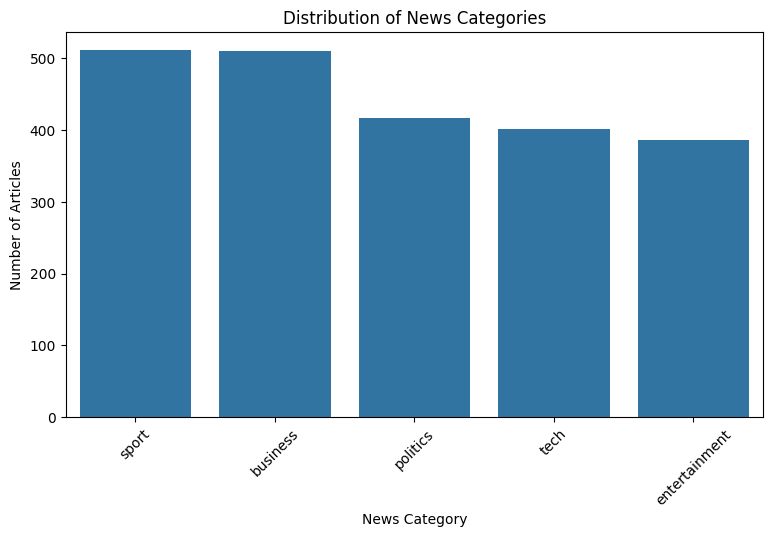

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x='category',
    order=df['category'].value_counts().index
)
plt.title("Distribution of News Categories")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.show()

#### Cell 11 – Check Empty and Missing Text

In [ ]:
print("Empty Titles:", (df['title'].str.strip() == '').sum())
print("Empty Contents:", (df['content'].str.strip() == '').sum())
print("Missing Titles:", df['title'].isnull().sum())
print("Missing Contents:", df['content'].isnull().sum())

Empty Titles: 0
Empty Contents: 0
Missing Titles: 0
Missing Contents: 0


#### Cell 12 – Duplicate Text Analysis

In [ ]:
print("Duplicate Titles:", df['title'].duplicated().sum())
print("Duplicate Contents:", df['content'].duplicated().sum())
print(
    "Duplicate News (Title + Content):",
    df.duplicated(subset=['title', 'content']).sum()
)

Duplicate Titles: 129
Duplicate Contents: 133
Duplicate News (Title + Content): 98


#### Cell 13 – Text Length Analysis

In [ ]:
df['title_char_length'] = df['title'].str.len()
df['content_char_length'] = df['content'].str.len()
df['title_word_count'] = df['title'].str.split().str.len()
df['content_word_count'] = df['content'].str.split().str.len()
print("Text Length Statistics:")
display(
    df[
        [
            'title_char_length',
            'content_char_length',
            'title_word_count',
            'content_word_count'
        ]
    ].describe()
)

Text Length Statistics:


,title_char_length,content_char_length,title_word_count,content_word_count
count,2225.000000,2225.000000,2225.000000,2225.000000
mean,31.367191,2232.793258,5.204494,378.835955
std,2.605422,1364.249946,0.865494,238.220755
min,16.000000,471.000000,3.000000,84.000000
25%,31.000000,1414.000000,5.000000,240.000000
50%,32.000000,1936.000000,5.000000,326.000000
75%,33.000000,2774.000000,6.000000,466.000000
max,52.000000,25454.000000,9.000000,4428.000000


#### Cell 14 – Article Length Distribution

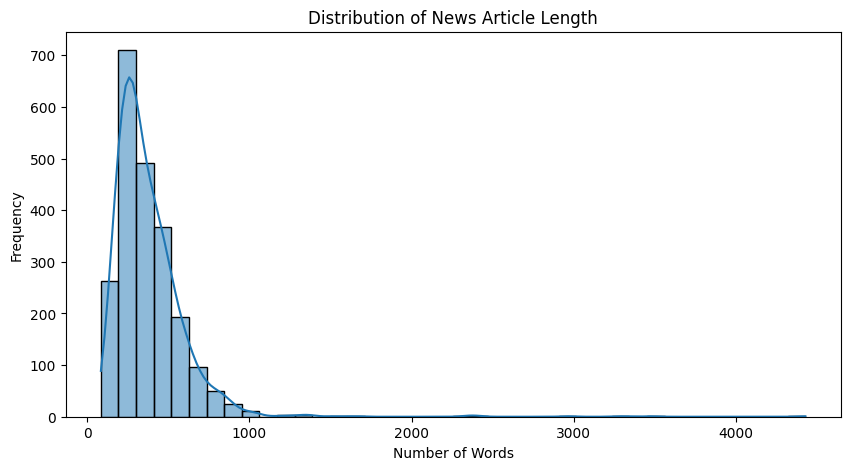

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x='content_word_count',
    bins=40,
    kde=True
)
plt.title("Distribution of News Article Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

#### Cell 15 – Average Article Length per Category

In [ ]:
category_length = df.groupby('category')['content_word_count'].mean()
print("Average Number of Words per Category:")
display(category_length)

Average Number of Words per Category:


,content_word_count
category,
business,323.484314
entertainment,325.196891
politics,448.884892
sport,324.369863
tech,497.428928


#### Cell 16 – Display Sample Articles

In [ ]:
for i in range(5):
    print("=" * 80)
    print("News Number:", i + 1)
    print("Category:", df.iloc[i]['category'])
    print("Title:", df.iloc[i]['title'])
    print("\nContent:")
    print(df.iloc[i]['content'])
    print("\n")

News Number: 1
Category: business
Title: Ad sales boost Time Warner profit

Content:
 Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.  The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.  Time Warner said on Friday that it now owns 8% of search-engine Google. But its own internet business, AOL, had has mixed fortunes. It lost 464,000 subscribers in the fourth quarter profits were lower than in the preceding three quarters. However, the company said AOL's underlying profit before exceptional items rose 8% on the back of stronger internet advertising revenues. It hopes to increase subscribers by offering the online service free to TimeWa

#### Cell 17 – Display One Article from Each Category

In [ ]:
for category in df['category'].unique():
    sample = df[df['category'] == category].sample(
        n=1,
        random_state=42
    ).iloc[0]
    print("=" * 80)
    print("Category:", category)
    print("Title:", sample['title'])
    print("\nContent:")
    print(sample['content'])
    print("\n")

Category: business
Title: Christmas sales worst since 1981

Content:
 UK retail sales fell in December, failing to meet expectations and making it by some counts the worst Christmas since 1981.  Retail sales dropped by 1% on the month in December, after a 0.6% rise in November, the Office for National Statistics (ONS) said. The ONS revised the annual 2004 rate of growth down from the 5.9% estimated in November to 3.2%. A number of retailers have already reported poor figures for December. Clothing retailers and non-specialist stores were the worst hit with only internet retailers showing any significant growth, according to the ONS.  The last time retailers endured a tougher Christmas was 23 years previously, when sales plunged 1.7%.  The ONS echoed an earlier caution from Bank of England governor Mervyn King not to read too much into the poor December figures. Some analysts put a positive gloss on the figures, pointing out that the non-seasonally-adjusted figures showed a performance 

#### Cell 18 – Check Duplicate News with Different Categories

In [ ]:
duplicate_news = df[
    df.duplicated(
        subset=['title', 'content'],
        keep=False
    )].sort_values(by=['title', 'category'])
print(
    "Number of rows involved in duplicate news:",
    len(duplicate_news)
)
display(
    duplicate_news[
        ['category', 'title', 'content']
    ].head(20)
)

Number of rows involved in duplicate news: 196


,category,title,content
1988,tech,'Brainwave' cap controls computer,A team of US researchers has shown that contr...
1989,tech,'Brainwave' cap controls computer,A team of US researchers has shown that contr...
954,politics,'Debate needed' on donations cap,A cap on donations to political parties shoul...
1193,politics,'Debate needed' on donations cap,A cap on donations to political parties shoul...
1003,politics,'Super union' merger plan touted,Two of Britain's big trade unions could merge...
1186,politics,'Super union' merger plan touted,Two of Britain's big trade unions could merge...
1949,tech,'Ultimate game' award for Doom 3,Sci-fi shooter Doom 3 has blasted away the co...
1994,tech,'Ultimate game' award for Doom 3,Sci-fi shooter Doom 3 has blasted away the co...
1992,tech,2D Metal Slug offers retro fun,"Like some drill sergeant from the past, Metal..."
2056,tech,2D Metal Slug offers retro fun,"Like some drill sergeant from the past, Metal..."


#### Cell 19 – Original Category Percentages

In [ ]:
print("Category Distribution:")
print(df['category'].value_counts())
print("\nCategory Percentages:")
print(
    (df['category'].value_counts(normalize=True) * 100).round(2)
)

Category Distribution:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64

Category Percentages:
category
sport            22.97
business         22.92
politics         18.74
tech             18.02
entertainment    17.35
Name: proportion, dtype: float64


#### Cell 20 – Check Conflicting Categories

In [ ]:
duplicate_groups = (
    df.groupby(['title', 'content'])['category']
    .nunique()
)
conflicting_news = duplicate_groups[duplicate_groups > 1]
print(
    "Number of news articles with conflicting categories:",
    len(conflicting_news)
)

Number of news articles with conflicting categories: 0


#### Cell 20.2 – Analyze Duplicate Patterns Before Cleaning

This check distinguishes repeated titles, repeated contents, and exact duplicate articles. A repeated title alone does not mean two articles are duplicates.

In [ ]:
# Analyze duplicate patterns before cleaning

title_dup = df['title'].duplicated(keep=False)
content_dup = df['content'].duplicated(keep=False)
both_dup = df.duplicated(subset=['title', 'content'], keep=False)

print("Total rows:", len(df))
print("Rows with duplicated titles:", title_dup.sum())
print("Rows with duplicated contents:", content_dup.sum())
print("Rows with duplicated title + content:", both_dup.sum())

# Same title but different content
same_title_diff_content = (
    df.groupby('title')['content']
      .nunique()
      .gt(1)
)

print(
    "Titles shared by multiple different contents:",
    same_title_diff_content.sum()
)

# Same content but different titles
same_content_diff_title = (
    df.groupby('content')['title']
      .nunique()
      .gt(1)
)

print(
    "Contents shared by multiple different titles:",
    same_content_diff_title.sum()
)

Total rows: 2225
Rows with duplicated titles: 258
Rows with duplicated contents: 266
Rows with duplicated title + content: 196
Titles shared by multiple different contents: 31
Contents shared by multiple different titles: 35


### Section 2: Data Cleaning

#### Cell 21 – Create Clean Dataset and Remove Duplicates


In [ ]:
df_clean = df.copy()

# Normalize extra whitespace in title and content
df_clean['title_clean'] = (
    df_clean['title']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

df_clean['content_clean'] = (
    df_clean['content']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

In [ ]:
# Check label consistency among exact duplicate articles

duplicate_label_check = (
    df_clean.groupby(['title_clean', 'content_clean'])['category']
            .nunique()
)

label_conflicts = duplicate_label_check[
    duplicate_label_check > 1
]

print(
    "Duplicate groups with conflicting labels:",
    len(label_conflicts)
)

Duplicate groups with conflicting labels: 0


In [ ]:
# Remove exact duplicate articles only
# An article is considered a duplicate when both normalized title and normalized content are identical.

before = len(df_clean)

df_clean = (
    df_clean
    .drop_duplicates(
        subset=['title_clean', 'content_clean'],
        keep='first'
    )
    .reset_index(drop=True)
)

after = len(df_clean)

print("Rows before duplicate removal:", before)
print("Exact duplicate rows removed:", before - after)
print("Rows after duplicate removal:", after)

Rows before duplicate removal: 2225
Exact duplicate rows removed: 100
Rows after duplicate removal: 2125


#### Cell 22 – Verify Clean Dataset

In [ ]:
print("Cleaned Dataset Shape:", df_clean.shape)
print("\nMissing Values:")
print(df_clean.isnull().sum())
print("\nCategory Distribution:")
print(df_clean['category'].value_counts())

Cleaned Dataset Shape: (2125, 10)

Missing Values:
category               0
filename               0
title                  0
content                0
title_char_length      0
content_char_length    0
title_word_count       0
content_word_count     0
title_clean            0
content_clean          0
dtype: int64

Category Distribution:
category
business         503
sport            503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64


#### Cell 23 – Define Stopwords

In [ ]:
extra_stopwords = {
    "aren", "couldn", "didn", "doesn", "don", "hadn",
    "hasn", "haven", "isn", "ll", "mustn", "shouldn",
    "ve", "wasn", "weren", "wouldn"
}
stop_words = set(ENGLISH_STOP_WORDS) | extra_stopwords
print("Scikit-learn stopwords:", len(ENGLISH_STOP_WORDS))
print("Additional stopwords:", len(extra_stopwords))
print("Total unique stopwords:", len(stop_words))

Scikit-learn stopwords: 318
Additional stopwords: 16
Total unique stopwords: 334


#### Cell 24 – Define Text Cleaning Function


In [ ]:
def clean_text(title, content):
    # Step 1: Combine title + space + content
    text = str(title) + ' ' + str(content)

    # Step 2: Normalize extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Step 3: Decode HTML entities
    text = html.unescape(text)

    # Step 4: Remove HTML tags
    text = re.sub(r'<[^>]*>', ' ', text)

    # Step 5: Remove URLs
    text = re.sub(
        r'https?://\S+|www\.\S+',
        ' ',
        text,
        flags=re.IGNORECASE
    )

    # Step 6: Remove accents and non-ASCII characters
    text = unicodedata.normalize('NFKD', text)
    text = text.encode('ascii', 'ignore').decode('ascii')

    # Step 7: Convert to lowercase
    text = text.lower()

    # Step 8: Replace anything other than a-z with spaces
    text = re.sub(r'[^a-z]', ' ', text)

    # Step 9: Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    # Step 10: Remove words shorter than 2 characters
    words = [word for word in words if len(word) >= 2]

    # Normalize spaces
    return ' '.join(words)

#### Cell 25 – Golden Examples Test



In [ ]:
golden_examples = [
    {
        "input": (
            "<p>Shares in BBC's parent rose 12.5% to &#163;1.8m "
            "&amp; analysts don't expect more.</p>"
        ),
        "expected": "shares bbc parent rose analysts expect"
    },
    {
        "input": (
            "Jos&#233; Mourinho's side won 3-0; "
            "visit http://example.com/news now!"
        ),
        "expected": "jose mourinho won visit"
    },
    {
        "input": (
            "Mr Brown's U.S. budget deficit - worth "
            "$671.7bn (£484bn) - hit a record."
        ),
        "expected": "mr brown budget deficit worth bn bn hit record"
    },
    {
        "input": (
            "  They've said we'll see: TV, PC and EU rules "
            "for 2004-05 won't change.  "
        ),
        "expected": "said tv pc eu rules won change"
    },
    {
        "input": "&#163;1.8m indecency fine for Viacom",
        "expected": "indecency fine viacom"
    }
]

all_passed = True

for i, ex in enumerate(golden_examples):
    cleaned = clean_text("", ex["input"])

    if cleaned == ex["expected"]:
        print(f"Example {i+1}: PASS")
    else:
        print(
            f"Example {i+1}: FAIL "
            f"(Expected: '{ex['expected']}', Got: '{cleaned}')"
        )
        all_passed = False

if all_passed:
    print("\nOverall: 5/5 PASS")

Example 1: PASS
Example 2: PASS
Example 3: PASS
Example 4: PASS
Example 5: PASS

Overall: 5/5 PASS


#### Cell 26 – Apply Cleaning to All Articles

In [ ]:
# Apply cleaning to all articles
df_clean['text'] = df_clean.apply(
    lambda row: clean_text(
        row['title_clean'],
        row['content_clean']
    ),
    axis=1
)
print("Text cleaning completed successfully!")
print("\nOriginal Text:")
print(
    df_clean['title_clean'].iloc[0] + ' ' +
    df_clean['content_clean'].iloc[0][:300]
)
print("\nCleaned Text:")
print(df_clean['text'].iloc[0][:500])

Text cleaning completed successfully!

Original Text:
Ad sales boost Time Warner profit Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier. The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said four

Cleaned Text:
ad sales boost time warner profit quarterly profits media giant timewarner jumped bn months december year earlier firm biggest investors google benefited sales high speed internet connections higher advert sales timewarner said fourth quarter sales rose bn bn profits buoyed gains offset profit dip warner bros users aol time warner said friday owns search engine google internet business aol mixed fortunes lost subscribers fourth quarter profits lower preceding quarters company said aol underlying


#### Cell 27 – Vocabulary Before and After Cleaning

In [ ]:
# Vocabulary before cleaning
vocab_before = set(
    ' '.join(
        df_clean['title_clean'] + ' ' + df_clean['content_clean']
    ).lower().split()
)
# Vocabulary after cleaning
vocab_after = set(
    ' '.join(df_clean['text']).split()
)
print("Vocabulary before cleaning:", len(vocab_before))
print("Vocabulary after cleaning:", len(vocab_after))
print(
    "Vocabulary reduction:",
    len(vocab_before) - len(vocab_after)
)

Vocabulary before cleaning: 60616
Vocabulary after cleaning: 27564
Vocabulary reduction: 33052


#### Cell 28 – Create Model Dataset and Keep IDs

In [ ]:
df_clean['ID'] = (
    df_clean['category'] + '/' + df_clean['filename']
)
model_df = df_clean[
    ['ID', 'text', 'category']].copy()
X = model_df['text']
y = model_df['category']
print("Model Dataset Shape:", model_df.shape)
print("\nMissing Values:")
print(model_df[['text', 'category']].isnull().sum())
print("\nEmpty Cleaned Texts:", (X.str.len() == 0).sum())
print("\nDuplicate Cleaned Texts:", X.duplicated().sum())
print("\nCategory Distribution:")
print(y.value_counts())

Model Dataset Shape: (2125, 3)

Missing Values:
text        0
category    0
dtype: int64

Empty Cleaned Texts: 0

Duplicate Cleaned Texts: 6

Category Distribution:
category
business         503
sport            503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64


### Section 3: Train / Validation / Test Split

#### Cell 29 – Split the Dataset


### Data Splitting Strategy

We used `StratifiedGroupKFold` to split the dataset into training, validation, and testing sets.

- **Grouping:** Ensures that records with identical cleaned text remain in the same fold, preventing duplicate-text leakage across different datasets.
- **Stratification:** Attempts to preserve the distribution of target categories across folds.
- **20 Folds:** The dataset is divided into 20 folds.
- **Split Allocation:** We combine 14 folds for training, 3 for validation, and 3 for testing.
- **Optimization:** Instead of assigning folds sequentially, we search for the combination that minimizes deviations in class distributions and split sizes from their target values.

This approach balances three goals: preventing duplicate-text leakage, maintaining class distribution, and achieving approximately 70% training, 15% validation, and 15% testing data.

**Note:** Stratification does not guarantee perfectly identical class distributions across the final splits.

### Generate Stratified Group Folds

generating 20 stratified folds using StratifiedGroupKFold.

The cleaned article text is used as the grouping variable to ensure that identical texts remain within the same fold, preventing duplicate-text leakage.

Stratification helps maintain a balanced distribution of article categories across the folds.

### Note on Test Set Usage

Only the class distribution of each fold is used to decide which folds form the training, validation and test sets. No model is involved, and the test set is not used for training or for hyperparameter selection.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Define groups and target labels
groups = model_df['text']
y = model_df['category']

# Initialize StratifiedGroupKFold
sgkf = StratifiedGroupKFold(
    n_splits=20,
    shuffle=True,
    random_state=42
)

# Generate the folds
folds = list(
    sgkf.split(
        model_df,
        y,
        groups
    )
)

print("Number of folds:", len(folds))
print("Total records:", sum(len(fold[1]) for fold in folds))

Number of folds: 20
Total records: 2125


### Prepare Fold-Level Statistics

calculating the number of records and the category distribution in each fold.

These statistics are used to evaluate different combinations of folds and select balanced training, validation, and test sets.

In [ ]:
# Prepare fold-level statistics for split optimization

n_classes = y.nunique()
n_folds = len(folds)

fold_class_counts = np.zeros((n_folds, n_classes), dtype=int)

classes = sorted(y.unique())

for i, (_, fold_idx) in enumerate(folds):
    fold_labels = y.iloc[fold_idx]

    fold_class_counts[i] = (
        fold_labels.value_counts()
        .reindex(classes, fill_value=0)
        .values
    )

fold_sizes = np.array([
    len(fold[1]) for fold in folds
])

print("Number of folds:", n_folds)
print("Classes:", classes)
print("Total records:", fold_sizes.sum())
print("Fold sizes:", fold_sizes)
print("Class counts shape:", fold_class_counts.shape)

Number of folds: 20
Classes: ['business', 'entertainment', 'politics', 'sport', 'tech']
Total records: 2125
Fold sizes: [106 106 106 105 107 106 106 106 106 107 106 107 107 107 106 107 106 106
 107 105]
Class counts shape: (20, 5)


### Optimize Train, Validation, and Test Splits

evaluating different combinations of folds to select training, validation, and test sets with similar category distributions.

The selected split consists of 14 folds for training, 3 folds for validation, and 3 folds for testing.

The optimization aims to minimize the differences between the category distributions of the three splits and the overall dataset.

In [ ]:
from itertools import combinations

# Target class distribution in the complete dataset
total_class_counts = fold_class_counts.sum(axis=0)
target_distribution = total_class_counts / total_class_counts.sum()

# All possible combinations of 3 folds
three_fold_combinations = np.array(
    list(combinations(range(n_folds - 3), 3))
)

best_score = float("inf")
best_train_folds = None
best_val_folds = None
best_test_folds = None

# Exhaustive search over all possible test and validation combinations
for test_combo in combinations(range(n_folds), 3):

    test_folds = np.array(test_combo)

    remaining_folds = np.array([
        i for i in range(n_folds)
        if i not in test_folds
    ])

    test_counts = fold_class_counts[test_folds].sum(axis=0)
    test_size = fold_sizes[test_folds].sum()

    val_combos = remaining_folds[three_fold_combinations]

    val_counts = fold_class_counts[val_combos].sum(axis=1)
    val_sizes = fold_sizes[val_combos].sum(axis=1)

    train_counts = total_class_counts - test_counts - val_counts
    train_sizes = fold_sizes.sum() - test_size - val_sizes

    # Calculate class distribution deviations
    test_distribution = test_counts / test_size
    val_distribution = val_counts / val_sizes[:, None]
    train_distribution = train_counts / train_sizes[:, None]

    class_score = (
        np.sum((test_distribution - target_distribution) ** 2)
        + np.sum((val_distribution - target_distribution) ** 2, axis=1)
        + np.sum((train_distribution - target_distribution) ** 2, axis=1)
    )

    # Calculate split-size deviations from target sizes
    size_score = (
        ((test_size - 0.15 * len(model_df)) / len(model_df)) ** 2
        + ((val_sizes - 0.15 * len(model_df)) / len(model_df)) ** 2
        + ((train_sizes - 0.70 * len(model_df)) / len(model_df)) ** 2
    )

    scores = class_score + size_score

    best_position = np.argmin(scores)

    if scores[best_position] < best_score:
        best_score = scores[best_position]

        best_test_folds = test_folds.copy()
        best_val_folds = val_combos[best_position].copy()

        best_train_folds = np.array([
            i for i in range(n_folds)
            if i not in best_test_folds
            and i not in best_val_folds
        ])

# Create the optimized indices
train_idx = np.concatenate([
    folds[i][1] for i in best_train_folds
])

val_idx = np.concatenate([
    folds[i][1] for i in best_val_folds
])

test_idx = np.concatenate([
    folds[i][1] for i in best_test_folds
])

# Create the optimized datasets
X_train = model_df.iloc[train_idx]['text']
y_train = model_df.iloc[train_idx]['category']

X_val = model_df.iloc[val_idx]['text']
y_val = model_df.iloc[val_idx]['category']

X_test = model_df.iloc[test_idx]['text']
y_test = model_df.iloc[test_idx]['category']

print("Best score:", best_score)
print("Train folds:", best_train_folds + 1)
print("Validation folds:", best_val_folds + 1)
print("Test folds:", best_test_folds + 1)

print("\nOptimized split sizes:")
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))


Best score: 9.793087861004757e-05
Train folds: [ 1  2  3  5  6  7  8 10 11 14 15 17 19 20]
Validation folds: [ 9 12 18]
Test folds: [ 4 13 16]

Optimized split sizes:
Train: 1487
Validation: 319
Test: 319
Total: 2125


#### Cell 30 – Check Class Distribution in Each Split

In [ ]:
# Compare category distribution across optimized splits

for split_name, split_labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{split_name} Distribution:")
    print(
        split_labels
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .sort_index()
    )


Train Distribution:
category
business         23.67
entertainment    17.48
politics         18.83
sport            23.67
tech             16.34
Name: proportion, dtype: float64

Validation Distribution:
category
business         23.20
entertainment    17.24
politics         19.44
sport            23.82
tech             16.30
Name: proportion, dtype: float64

Test Distribution:
category
business         24.14
entertainment    16.93
politics         19.12
sport            23.51
tech             16.30
Name: proportion, dtype: float64


In [ ]:
# Check duplicate-text overlap across optimized splits

train_texts = set(X_train)
val_texts = set(X_val)
test_texts = set(X_test)

train_val_overlap = train_texts.intersection(val_texts)
train_test_overlap = train_texts.intersection(test_texts)
val_test_overlap = val_texts.intersection(test_texts)

print("Train-Validation overlap:", len(train_val_overlap))
print("Train-Test overlap:", len(train_test_overlap))
print("Validation-Test overlap:", len(val_test_overlap))

print(
    "\nNo duplicate leakage:",
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
)

print("\nTotal assigned indices:", len(train_idx) + len(val_idx) + len(test_idx))
print("Unique assigned indices:", len(np.unique(
    np.concatenate([train_idx, val_idx, test_idx])
)))

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0

No duplicate leakage: True

Total assigned indices: 2125
Unique assigned indices: 2125


In [ ]:
# Verify that all folds form a complete, non-overlapping partition

all_fold_indices = np.concatenate([
    fold[1] for fold in folds
])

print("Total assigned indices:", len(all_fold_indices))
print("Unique assigned indices:", len(np.unique(all_fold_indices)))
print("Original dataset size:", len(model_df))
print(
    "All records assigned exactly once:",
    len(all_fold_indices) == len(model_df)
    and len(np.unique(all_fold_indices)) == len(model_df)
)

Total assigned indices: 2125
Unique assigned indices: 2125
Original dataset size: 2125
All records assigned exactly once: True


### Section 4: TF-IDF Feature Extraction

#### Cell 31 – Initialize and Fit TF-IDF

In [ ]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=3,
    max_df=0.8,
    max_features=None,
    sublinear_tf=True,
    stop_words=None
)
# Fit ONLY on training data
X_train_tfidf = tfidf.fit_transform(X_train)
# Transform validation and testing data
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

#### Cell 32 – Check TF-IDF Shapes and Number of Features

In [ ]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print(
    "\nNumber of learned features:",
    len(tfidf.get_feature_names_out())
)

Training TF-IDF shape: (1487, 10076)
Validation TF-IDF shape: (319, 10076)
Testing TF-IDF shape: (319, 10076)

Number of learned features: 10076


#### Cell 33 – Dataset and Feature Fingerprints

In [ ]:
import hashlib
import sklearn


def sha256_fingerprint(values):
    """
    Sort values, join them using a newline, and return
    the first 16 characters of the SHA-256 hash.
    """
    text = '\n'.join(sorted(map(str, values)))
    return hashlib.sha256(text.encode('utf-8')).hexdigest()[:16]


# Get IDs using the original model_df index
cleaned_ids = model_df.loc[X.index, 'ID']
train_ids = model_df.loc[X_train.index, 'ID']
val_ids = model_df.loc[X_val.index, 'ID']
test_ids = model_df.loc[X_test.index, 'ID']

# Fingerprints for dataset IDs
print("Dataset ID Fingerprints")
print("-" * 40)
print("Cleaned:", sha256_fingerprint(cleaned_ids))
print("Train:  ", sha256_fingerprint(train_ids))
print("Validation:", sha256_fingerprint(val_ids))
print("Test:   ", sha256_fingerprint(test_ids))

# Fingerprint for TF-IDF feature names
feature_names = tfidf.get_feature_names_out()

print("\nTF-IDF Feature Fingerprint")
print("-" * 40)
print("Feature fingerprint:", sha256_fingerprint(feature_names))

# Vocabulary size
print("\nTF-IDF Vocabulary Size")
print("-" * 40)
print("Number of features:", len(feature_names))

# Scikit-learn version
print("\nEnvironment")
print("-" * 40)
print("scikit-learn version:", sklearn.__version__)

Dataset ID Fingerprints
----------------------------------------
Cleaned: b97f712443c9995e
Train:   183dbcde9e18f709
Validation: fa7217dabc413590
Test:    8fbca1cd31e1d902

TF-IDF Feature Fingerprint
----------------------------------------
Feature fingerprint: 6f7678ff5ff04467

TF-IDF Vocabulary Size
----------------------------------------
Number of features: 10076

Environment
----------------------------------------
scikit-learn version: 1.6.1


---
### Section 5: Logistic Regression Model


#### Cell 34 – Model Preparation

The test set is not used for model training or hyperparameter selection. It is reserved for final model evaluation after the split allocation has been determined.

The models and figures directories are created to store trained models and generated visualizations.

In [ ]:
# Shared Imports and Setup

import os

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import learning_curve


MODELS_DIR = 'models'
FIGURES_DIR = 'figures'

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)


RANDOM_STATE = 42

In [ ]:
# Verify shared model inputs

required_variables = [
    "X_train_tfidf",
    "X_val_tfidf",
    "y_train",
    "y_val"
]

missing_variables = [
    var for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing required variables: {missing_variables}"
    )

print("All required variables are available.")
print()
print("X_train_tfidf shape:", X_train_tfidf.shape)
print("X_val_tfidf shape:", X_val_tfidf.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)

All required variables are available.

X_train_tfidf shape: (1487, 10076)
X_val_tfidf shape: (319, 10076)
y_train shape: (1487,)
y_val shape: (319,)


#### Cell 35 – Logistic Regression Baseline


In [ ]:
# Baseline Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Initialize the baseline model with default hyperparameters
lr_baseline_model = LogisticRegression(random_state=42)

# Train the model
lr_baseline_model.fit(X_train_tfidf, y_train)

# Predict validation labels
lr_y_val_pred_baseline = lr_baseline_model.predict(X_val_tfidf)

# Calculate validation metrics
lr_baseline_accuracy = accuracy_score(
    y_val,
    lr_y_val_pred_baseline
)

lr_baseline_macro_f1 = f1_score(
    y_val,
    lr_y_val_pred_baseline,
    average="macro"
)

print("Baseline Logistic Regression")
print("-" * 35)
print(f"Validation Accuracy : {lr_baseline_accuracy:.4f}")
print(f"Validation Macro-F1 : {lr_baseline_macro_f1:.4f}")

Baseline Logistic Regression
-----------------------------------
Validation Accuracy : 0.9781
Validation Macro-F1 : 0.9771


#### Cell 36 – Hyperparameter Tuning



In [ ]:
# Logistic Regression Hyperparameter Tuning

from itertools import product
from sklearn.exceptions import ConvergenceWarning
import warnings
import pandas as pd

C_values = [0.1, 1, 10, 100, 1000]
class_weight_values = [None, "balanced"]

lr_tuning_results = []

for C, class_weight in product(C_values, class_weight_values):

    print(f"\nTraining: C={C}, class_weight={class_weight}")

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always")

        lr_model = LogisticRegression(
            C=C,
            class_weight=class_weight,
            solver="lbfgs",
            max_iter=1000,
            random_state=42
        )

        lr_model.fit(X_train_tfidf, y_train)

    # Validation predictions
    lr_y_val_pred = lr_model.predict(X_val_tfidf)

    # Evaluation metrics
    lr_accuracy = accuracy_score(y_val, lr_y_val_pred)

    lr_macro_f1 = f1_score(
        y_val,
        lr_y_val_pred,
        average="macro"
    )

    # Check convergence warnings
    convergence_warning = any(
        issubclass(w.category, ConvergenceWarning)
        for w in caught_warnings
    )

    lr_tuning_results.append({
        "C": C,
        "class_weight": class_weight,
        "accuracy": lr_accuracy,
        "macro_f1": lr_macro_f1,
        "convergence_warning": convergence_warning
    })

# Create results table
lr_tuning_results_df = pd.DataFrame(lr_tuning_results)

lr_tuning_results_df = lr_tuning_results_df.sort_values(
    by="macro_f1",
    ascending=False
).reset_index(drop=True)

print("\nHyperparameter Tuning Results")
display(lr_tuning_results_df)


Training: C=0.1, class_weight=None

Training: C=0.1, class_weight=balanced

Training: C=1, class_weight=None

Training: C=1, class_weight=balanced

Training: C=10, class_weight=None

Training: C=10, class_weight=balanced

Training: C=100, class_weight=None

Training: C=100, class_weight=balanced

Training: C=1000, class_weight=None

Training: C=1000, class_weight=balanced

Hyperparameter Tuning Results


,C,class_weight,accuracy,macro_f1,convergence_warning
0,10.0,None,0.978056,0.977844,False
1,1000.0,balanced,0.978056,0.977091,False
2,1000.0,None,0.978056,0.977091,False
3,1.0,None,0.978056,0.977052,False
4,10.0,balanced,0.974922,0.974901,False
5,1.0,balanced,0.974922,0.974901,False
6,100.0,balanced,0.974922,0.974141,False
7,100.0,None,0.974922,0.974141,False
8,0.1,balanced,0.971787,0.971159,False
9,0.1,None,0.915361,0.912851,False


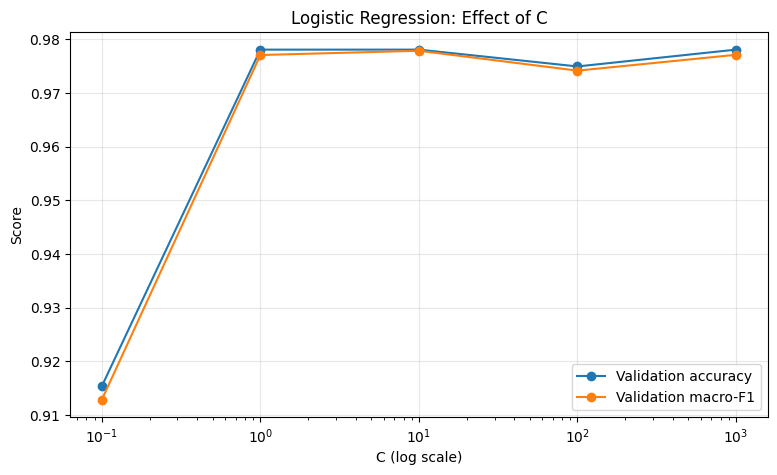

In [ ]:
# Effect of C on Accuracy

lr_c_plot_df = lr_tuning_results_df[
    lr_tuning_results_df["class_weight"].isna()
].sort_values("C")

plt.figure(figsize=(9, 5))

plt.plot(
    lr_c_plot_df["C"],
    lr_c_plot_df["accuracy"],
    marker="o",
    label="Validation accuracy"
)

plt.plot(
    lr_c_plot_df["C"],
    lr_c_plot_df["macro_f1"],
    marker="o",
    label="Validation macro-F1"
)

plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Score")
plt.title("Logistic Regression: Effect of C")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(
    os.path.join(FIGURES_DIR, "lr_tuning_C.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

#### Cell 37 – Model Selection



In [ ]:
# Select the best Logistic Regression configuration

lr_tuning_selection_df = lr_tuning_results_df.copy()

# Apply the predefined tie-breaking rule
lr_tuning_selection_df["class_weight_priority"] = (
    lr_tuning_selection_df["class_weight"].map({
        None: 0,
        "balanced": 1
    })
)

lr_best_row = lr_tuning_selection_df.sort_values(
    by=["macro_f1", "C", "class_weight_priority"],
    ascending=[False, True, True]
).iloc[0]

lr_best_C = lr_best_row["C"]
lr_best_class_weight = lr_best_row["class_weight"]

print("Selected Logistic Regression Configuration")
print("-" * 45)
print(f"C                    : {lr_best_C}")
print(f"class_weight         : {lr_best_class_weight}")
print(f"Validation Accuracy  : {lr_best_row['accuracy']:.6f}")
print(f"Validation Macro-F1  : {lr_best_row['macro_f1']:.6f}")
print(f"Convergence Warning  : {lr_best_row['convergence_warning']}")

Selected Logistic Regression Configuration
---------------------------------------------
C                    : 10.0
class_weight         : None
Validation Accuracy  : 0.978056
Validation Macro-F1  : 0.977844
Convergence Warning  : False


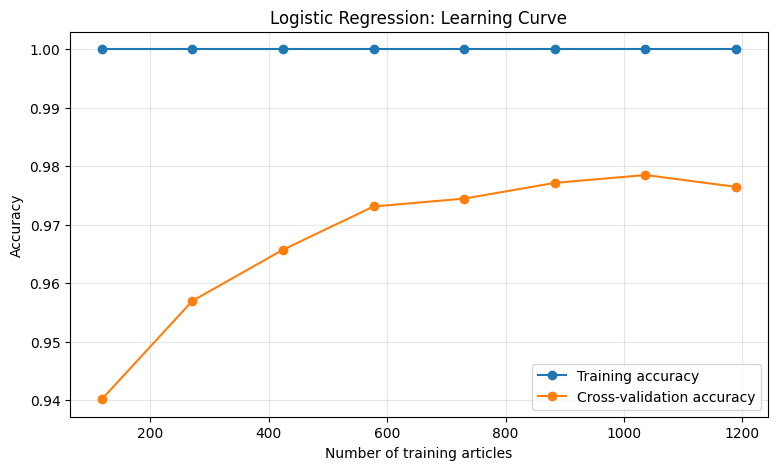

In [ ]:
# Logistic Regression Learning Curve

lr_lc_pipeline = Pipeline([
    (
        "tfidf",
        clone(tfidf)
    ),
    (
        "lr",
        LogisticRegression(
            C=lr_best_C,
            class_weight=lr_best_class_weight,
            solver="lbfgs",
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

lr_train_sizes, lr_train_scores, lr_val_scores = learning_curve(
    lr_lc_pipeline,
    X_train,
    y_train,
    train_sizes=np.linspace(0.1, 1.0, 8),
    cv=5,
    scoring="accuracy",
    shuffle=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

plt.figure(figsize=(9, 5))

plt.plot(
    lr_train_sizes,
    lr_train_scores.mean(axis=1),
    marker="o",
    label="Training accuracy"
)

plt.plot(
    lr_train_sizes,
    lr_val_scores.mean(axis=1),
    marker="o",
    label="Cross-validation accuracy"
)

plt.xlabel("Number of training articles")
plt.ylabel("Accuracy")
plt.title("Logistic Regression: Learning Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(
    os.path.join(FIGURES_DIR, "lr_learning_curve.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

#### Cell 38 – Final Model Training


In [ ]:
# Train the final Logistic Regression model

lr_final_model = LogisticRegression(
    C=lr_best_C,
    class_weight=lr_best_class_weight,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

# Train using the training set only
lr_final_model.fit(X_train_tfidf, y_train)

print("Final Logistic Regression model trained successfully.")
print("-" * 45)
print(f"C            : {lr_best_C}")
print(f"class_weight : {lr_best_class_weight}")
print(f"Training samples: {X_train_tfidf.shape[0]}")
print(f"Features        : {X_train_tfidf.shape[1]}")

Final Logistic Regression model trained successfully.
---------------------------------------------
C            : 10.0
class_weight : None
Training samples: 1487
Features        : 10076


#### Cell 39 – Final Test Evaluation



In [ ]:
# Final Test Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict test labels
lr_y_test_pred = lr_final_model.predict(X_test_tfidf)

# Fixed class order
lr_class_order = [
    "business",
    "entertainment",
    "politics",
    "sport",
    "tech"
]

# Overall accuracy
lr_test_accuracy = accuracy_score(y_test, lr_y_test_pred)

# Per-class metrics
lr_precision, lr_recall, lr_f1, lr_support = precision_recall_fscore_support(
    y_test,
    lr_y_test_pred,
    labels=lr_class_order,
    zero_division=0
)

lr_test_metrics_df = pd.DataFrame({
    "class": lr_class_order,
    "precision": lr_precision,
    "recall": lr_recall,
    "f1": lr_f1,
    "support": lr_support
})

# Macro averages
lr_test_macro_precision, lr_test_macro_recall, lr_test_macro_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        lr_y_test_pred,
        average="macro",
        zero_division=0
    )
)

# Weighted averages
lr_test_weighted_precision, lr_test_weighted_recall, lr_test_weighted_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        lr_y_test_pred,
        average="weighted",
        zero_division=0
    )
)

print("Final Test Accuracy:", f"{lr_test_accuracy:.4f}")

print("\nPer-Class Metrics:")
display(lr_test_metrics_df)

print("\nMacro Average")
print(f"Precision: {lr_test_macro_precision:.4f}")
print(f"Recall   : {lr_test_macro_recall:.4f}")
print(f"F1       : {lr_test_macro_f1:.4f}")

print("\nWeighted Average")
print(f"Precision: {lr_test_weighted_precision:.4f}")
print(f"Recall   : {lr_test_weighted_recall:.4f}")
print(f"F1       : {lr_test_weighted_f1:.4f}")

Final Test Accuracy: 0.9812

Per-Class Metrics:


,class,precision,recall,f1,support
0,business,0.986842,0.974026,0.980392,77
1,entertainment,1.000000,0.962963,0.981132,54
2,politics,0.953125,1.000000,0.976000,61
3,sport,0.986842,1.000000,0.993377,75
4,tech,0.980392,0.961538,0.970874,52



Macro Average
Precision: 0.9814
Recall   : 0.9797
F1       : 0.9804

Weighted Average
Precision: 0.9816
Recall   : 0.9812
F1       : 0.9812


Confusion Matrix
Class order: ['business', 'entertainment', 'politics', 'sport', 'tech']


,business,entertainment,politics,sport,tech
business,75,0,1,0,1
entertainment,0,52,2,0,0
politics,0,0,61,0,0
sport,0,0,0,75,0
tech,1,0,0,1,50


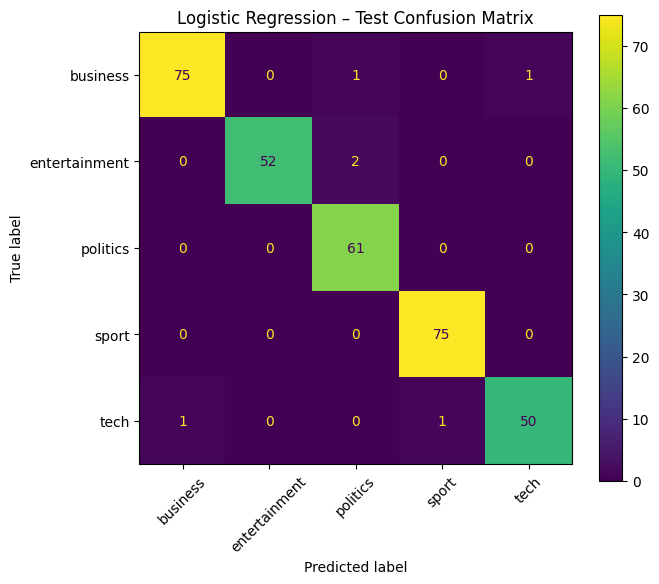

In [ ]:
# Confusion Matrix

lr_cm = confusion_matrix(
    y_test,
    lr_y_test_pred,
    labels=lr_class_order
)

print("Confusion Matrix")
print("Class order:", lr_class_order)

display(
    pd.DataFrame(
        lr_cm,
        index=lr_class_order,
        columns=lr_class_order
    )
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=lr_class_order
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

ax.set_title("Logistic Regression – Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "confusion_matrix_lr.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

#### Cell 40 – Error Analysis



In [ ]:
# Identify misclassified articles

import numpy as np
import pandas as pd

lr_y_test_array = np.asarray(y_test)
lr_y_test_pred_array = np.asarray(lr_y_test_pred)
lr_misclassified_positions = np.flatnonzero(lr_y_test_array != lr_y_test_pred_array)
lr_misclassified_indices = y_test.index[lr_misclassified_positions]

lr_error_analysis_df = pd.DataFrame({
    "dataset_index": lr_misclassified_indices,
    "article_id": model_df.loc[lr_misclassified_indices, "ID"].values,
    "actual_class": lr_y_test_array[lr_misclassified_positions],
    "predicted_class": lr_y_test_pred_array[lr_misclassified_positions]
})

print("Error Analysis Summary")
print("-" * 35)
print("Total test articles:", len(y_test))
print("Correct predictions:", len(y_test) - len(lr_misclassified_positions))
print("Misclassified articles:", len(lr_misclassified_positions))
print("\nMisclassified Articles:")
display(lr_error_analysis_df)
print("\nConfusion between classes:")
display(lr_error_analysis_df.groupby(["actual_class", "predicted_class"]).size().reset_index(name="count"))


Error Analysis Summary
-----------------------------------
Total test articles: 319
Correct predictions: 313
Misclassified articles: 6

Misclassified Articles:


,dataset_index,article_id,actual_class,predicted_class
0,241,business/243.txt,business,tech
1,1908,tech/133.txt,tech,business
2,252,business/255.txt,business,politics
3,699,entertainment/202.txt,entertainment,politics
4,752,entertainment/257.txt,entertainment,politics
5,1919,tech/144.txt,tech,sport



Confusion between classes:


,actual_class,predicted_class,count
0,business,politics,1
1,business,tech,1
2,entertainment,politics,2
3,tech,business,1
4,tech,sport,1


#### Cell 41 – Locate Original Articles



In [ ]:
# Select up to 3 actual misclassified articles dynamically

selected_article_indices = (
    lr_error_analysis_df["dataset_index"]
    .head(3)
    .tolist()
)

lr_prediction_by_index = (
    lr_error_analysis_df
    .set_index("dataset_index")["predicted_class"]
)

for dataset_index in selected_article_indices:

    article = df_clean.loc[dataset_index]

    prediction = lr_prediction_by_index.loc[dataset_index]

    article_id = model_df.loc[dataset_index, "ID"]

    print("=" * 80)
    print(f"Dataset index: {dataset_index}")
    print(f"Article ID: {article_id}")
    print(f"Title: {article['title']}")
    print(f"Actual Category: {article['category']}")
    print(f"Predicted Category: {prediction}")
    print("-" * 80)
    print(article["content"])
    print()

Dataset index: 241
Article ID: business/243.txt
Title: Making your office work for you
Actual Category: business
Predicted Category: tech
--------------------------------------------------------------------------------
 Our mission to brighten up your working lives continues - and this time, we're taking a long hard look at your offices.  Over the next few months, our panel of experts will be listening to your gripes about where you work, and suggesting ways to make your workspace more efficient, more congenial or simply prettier. This week, we're hearing from Marianne Petersen, who is planning to convert a barn in Sweden into a base for her freelance writing work. Click on the link under her photograph to read her story, and then scroll down to see what the panel have to say. And if you want to take part in the series, go to the bottom of the story to find out how to get in touch.  Working from home presents a multitude of challenges. Understanding your work personality allows you to 

#### Cell 5.1 – Save the Logistic Regression model

The TF-IDF vectorizer (fitted on the training data only) and the final model are chained in one `Pipeline`, so it can be loaded later without retraining.

In [ ]:
import os
import joblib
from sklearn.pipeline import Pipeline

os.makedirs('models', exist_ok=True)

lr_pipeline = Pipeline([
    ('tfidf', tfidf),
    ('logreg', lr_final_model)
])

joblib.dump(lr_final_model, 'models/c_logreg.pkl')
joblib.dump(lr_pipeline, 'models/c_logreg_pipeline.pkl')

reloaded = joblib.load('models/c_logreg_pipeline.pkl')
same = (reloaded.predict(X_test) == lr_final_model.predict(X_test_tfidf)).all()
print("Reloaded pipeline gives identical test predictions:", bool(same))

Reloaded pipeline gives identical test predictions: True


## Section 6: Linear SVM

#### Cell 6.1 – Import Libraries for Section 6

Imports the Linear SVM, the pipeline tools and the evaluation metrics.

In [ ]:
import joblib
from sklearn.dummy import DummyClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


#### Cell 6.2 – Linear SVM Baseline

A Linear SVM with the default settings (`C = 1.0`) is trained on the training set and evaluated on the validation set. This is the reference point before tuning.

In [ ]:
svm_baseline = LinearSVC(
    random_state=RANDOM_STATE,
    max_iter=10000
)

svm_baseline.fit(X_train_tfidf, y_train)

baseline_train_acc = accuracy_score(
    y_train,
    svm_baseline.predict(X_train_tfidf)
)

baseline_val_pred = svm_baseline.predict(X_val_tfidf)
baseline_val_acc = accuracy_score(y_val, baseline_val_pred)
baseline_val_f1 = f1_score(y_val, baseline_val_pred, average='macro')

print("Baseline Linear SVM (default C = 1.0)")
print("-" * 40)
print("Training accuracy:   ", round(baseline_train_acc, 4))
print("Validation accuracy: ", round(baseline_val_acc, 4))
print("Validation macro F1: ", round(baseline_val_f1, 4))

print("\nValidation Classification Report:")
print(classification_report(y_val, baseline_val_pred, digits=4))

Baseline Linear SVM (default C = 1.0)
----------------------------------------
Training accuracy:    1.0
Validation accuracy:  0.9718
Validation macro F1:  0.9709

Validation Classification Report:
               precision    recall  f1-score   support

     business     0.9595    0.9595    0.9595        74
entertainment     0.9815    0.9636    0.9725        55
     politics     0.9667    0.9355    0.9508        62
        sport     1.0000    1.0000    1.0000        76
         tech     0.9455    1.0000    0.9720        52

     accuracy                         0.9718       319
    macro avg     0.9706    0.9717    0.9709       319
 weighted avg     0.9720    0.9718    0.9717       319



#### Cell 6.3 – Hyperparameter Tuning

`C` controls the regularization strength: a small `C` gives a simpler model with a wider margin, a large `C` fits the training data more closely. Each value is trained on the training set and scored on the validation set.

In [ ]:
C_values = [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100]

tuning_results = []

for C in C_values:

    model = LinearSVC(
        C=C,
        random_state=RANDOM_STATE,
        max_iter=10000
    )

    model.fit(X_train_tfidf, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train_tfidf))

    val_pred = model.predict(X_val_tfidf)
    val_acc = accuracy_score(y_val, val_pred)
    val_f1 = f1_score(y_val, val_pred, average='macro')

    tuning_results.append({
        'C': C,
        'train_accuracy': train_acc,
        'val_accuracy': val_acc,
        'val_macro_f1': val_f1
    })

tuning_df = pd.DataFrame(tuning_results)

print("Linear SVM tuning results:")
display(tuning_df.round(4))

Linear SVM tuning results:


,C,train_accuracy,val_accuracy,val_macro_f1
0,0.01,0.9583,0.9091,0.9059
1,0.05,0.9960,0.9718,0.9709
2,0.10,0.9980,0.9749,0.9741
3,0.50,1.0000,0.9718,0.9712
4,1.00,1.0000,0.9718,0.9709
5,5.00,1.0000,0.9718,0.9709
6,10.00,1.0000,0.9718,0.9709
7,50.00,1.0000,0.9749,0.9739
8,100.00,1.0000,0.9749,0.9739


#### Cell 6.4 – Effect of C on Accuracy

Training and validation accuracy for each value of `C`. A growing gap between the two curves means the model starts to overfit.

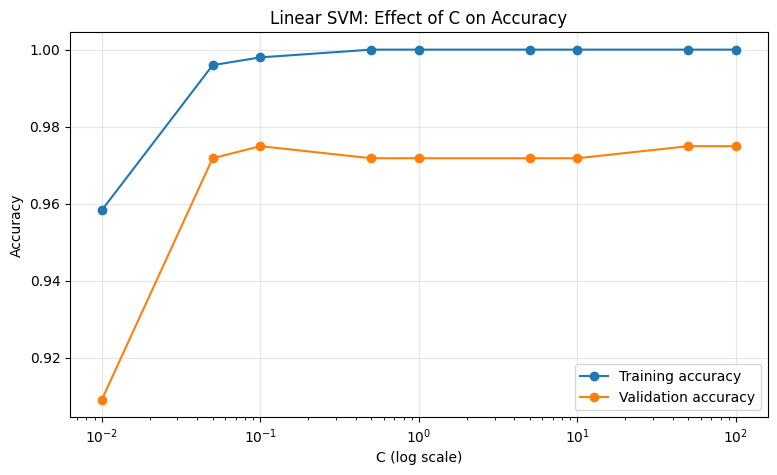

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    tuning_df['C'],
    tuning_df['train_accuracy'],
    marker='o',
    label='Training accuracy'
)

plt.plot(
    tuning_df['C'],
    tuning_df['val_accuracy'],
    marker='o',
    label='Validation accuracy'
)

plt.xscale('log')
plt.xlabel("C (log scale)")
plt.ylabel("Accuracy")
plt.title("Linear SVM: Effect of C on Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(
    os.path.join(FIGURES_DIR, 'svm_tuning_C.png'),
    dpi=150,
    bbox_inches='tight'
)
plt.show()

#### Cell 6.5 – Select the Best C

The `C` with the highest validation macro-F1 is selected, the same criterion used for Logistic Regression. If two values tie, the smaller `C` is kept.

In [ ]:
best_row = tuning_df.sort_values(
    by=['val_macro_f1', 'C'],
    ascending=[False, True]
).iloc[0]

best_C = float(best_row['C'])

print("Best C:", best_C)
print("Validation accuracy with best C:", round(best_row['val_accuracy'], 4))
print("Validation macro F1 with best C:", round(best_row['val_macro_f1'], 4))
print("\nImprovement over baseline (validation macro F1):",
      round(best_row['val_macro_f1'] - baseline_val_f1, 4))
print("Improvement over baseline (validation accuracy):",
      round(best_row['val_accuracy'] - baseline_val_acc, 4))

Best C: 0.1
Validation accuracy with best C: 0.9749
Validation macro F1 with best C: 0.9741

Improvement over baseline (validation macro F1): 0.0032
Improvement over baseline (validation accuracy): 0.0031


#### Cell 6.6 – Learning Curve

Training and cross-validation accuracy as the number of training articles grows (training data only). Curves that are high and close together mean the model generalizes well.

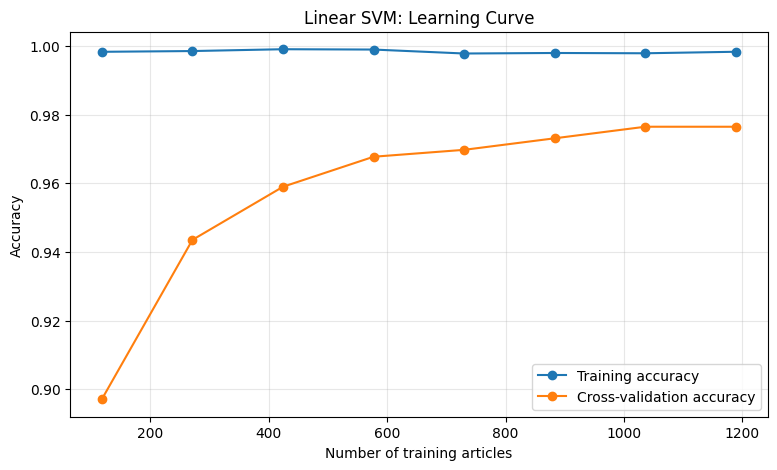

In [ ]:
lc_pipeline = Pipeline([
    ('tfidf', clone(tfidf)),
    ('svm', LinearSVC(C=best_C, random_state=RANDOM_STATE, max_iter=10000))
])

train_sizes, lc_train_scores, lc_val_scores = learning_curve(
    lc_pipeline,
    X_train,
    y_train,
    train_sizes=np.linspace(0.1, 1.0, 8),
    cv=5,
    scoring='accuracy',
    shuffle=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, lc_train_scores.mean(axis=1), marker='o', label='Training accuracy')
plt.plot(train_sizes, lc_val_scores.mean(axis=1), marker='o', label='Cross-validation accuracy')
plt.xlabel("Number of training articles")
plt.ylabel("Accuracy")
plt.title("Linear SVM: Learning Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(
    os.path.join(FIGURES_DIR, 'svm_learning_curve.png'),
    dpi=150,
    bbox_inches='tight'
)
plt.show()

#### Cell 6.7 – Sanity Checks

Two checks on the validation set: a model that always predicts the most frequent category, and the same SVM trained on shuffled labels. Both should be close to chance (about 0.20) and far below the real model.

In [ ]:
# 1) Majority-class baseline
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_tfidf, y_train)
dummy_val_acc = accuracy_score(y_val, dummy.predict(X_val_tfidf))

# 2) Shuffled-labels test
rng = np.random.RandomState(RANDOM_STATE)
y_train_shuffled = rng.permutation(y_train.values)

shuffled_model = LinearSVC(C=best_C, random_state=RANDOM_STATE, max_iter=10000)
shuffled_model.fit(X_train_tfidf, y_train_shuffled)
shuffled_val_acc = accuracy_score(y_val, shuffled_model.predict(X_val_tfidf))

print("Majority-class baseline (validation accuracy):", round(dummy_val_acc, 4))
print("Shuffled-labels SVM (validation accuracy):    ", round(shuffled_val_acc, 4))
print("Our Linear SVM (validation accuracy):         ", round(best_row['val_accuracy'], 4))

Majority-class baseline (validation accuracy): 0.232
Shuffled-labels SVM (validation accuracy):     0.2288
Our Linear SVM (validation accuracy):          0.9749


#### Cell 6.8 – Train the Final Linear SVM

The final model is trained on the training set with the selected `C`.

In [ ]:
svm_final = LinearSVC(
    C=best_C,
    random_state=RANDOM_STATE,
    max_iter=10000
)

svm_final.fit(X_train_tfidf, y_train)

print("Final Linear SVM trained with C =", best_C)
print("Classes:", list(svm_final.classes_))

Final Linear SVM trained with C = 0.1
Classes: ['business', 'entertainment', 'politics', 'sport', 'tech']


#### Cell 6.9 – Final Test Evaluation

The Linear SVM is evaluated on the test set once. The predictions are stored in `y_test_pred_svm` and reused in Sections 8 and 9.

In [ ]:
y_test_pred_svm = svm_final.predict(X_test_tfidf)

svm_test_accuracy = accuracy_score(y_test, y_test_pred_svm)
svm_test_macro_f1 = f1_score(y_test, y_test_pred_svm, average='macro')

print("Linear SVM - Test Set Results")
print("-" * 40)
print("Test accuracy:  ", round(svm_test_accuracy, 4))
print("Test macro F1:  ", round(svm_test_macro_f1, 4))

print("\nClassification Report (per class):")
print(classification_report(y_test, y_test_pred_svm, digits=4))

Linear SVM - Test Set Results
----------------------------------------
Test accuracy:   0.9749
Test macro F1:   0.9741

Classification Report (per class):
               precision    recall  f1-score   support

     business     0.9740    0.9740    0.9740        77
entertainment     1.0000    0.9630    0.9811        54
     politics     0.9524    0.9836    0.9677        61
        sport     0.9740    1.0000    0.9868        75
         tech     0.9800    0.9423    0.9608        52

     accuracy                         0.9749       319
    macro avg     0.9761    0.9726    0.9741       319
 weighted avg     0.9753    0.9749    0.9749       319



#### Cell 6.10 – Confusion Matrices

Counts, normalized by true category, and errors only (correct predictions removed so the confusions stand out).

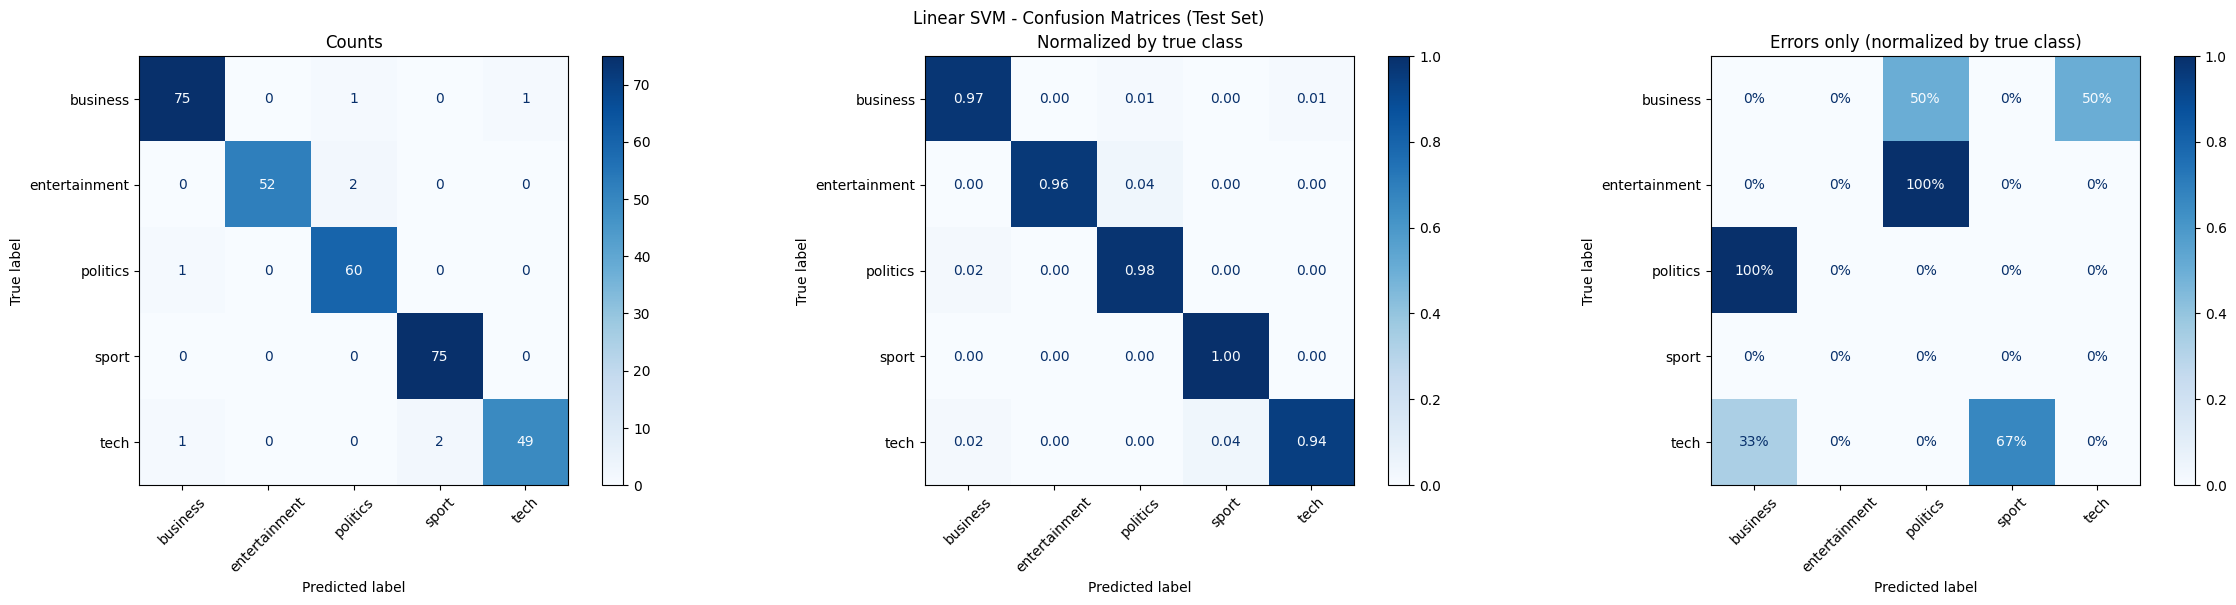

In [ ]:
class_names = svm_final.classes_
errors_weight = (y_test.values != y_test_pred_svm)

fig, axes = plt.subplots(1, 3, figsize=(24, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_svm,
    labels=class_names,
    cmap='Blues',
    xticks_rotation=45,
    ax=axes[0]
)
axes[0].set_title("Counts")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_svm,
    labels=class_names,
    normalize='true',
    values_format='.2f',
    cmap='Blues',
    xticks_rotation=45,
    ax=axes[1]
)
axes[1].set_title("Normalized by true class")

if errors_weight.sum() > 0:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_test_pred_svm,
        labels=class_names,
        sample_weight=errors_weight,
        normalize='true',
        values_format='.0%',
        cmap='Blues',
        xticks_rotation=45,
        ax=axes[2]
    )
    axes[2].set_title("Errors only (normalized by true class)")
else:
    axes[2].text(0.5, 0.5, "No misclassified articles", ha='center', va='center')
    axes[2].set_axis_off()

plt.suptitle("Linear SVM - Confusion Matrices (Test Set)")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, 'confusion_matrix_svm.png'),
    dpi=150,
    bbox_inches='tight'
)
plt.show()

#### Cell 6.11 – Top Words for Each Category



In [ ]:
feature_names = np.array(tfidf.get_feature_names_out())

print("Top 10 words per category (Linear SVM):\n")

for i, class_name in enumerate(svm_final.classes_):

    top_indices = np.argsort(svm_final.coef_[i])[-10:][::-1]

    print(f"{class_name:15s}:", ', '.join(feature_names[top_indices]))

Top 10 words per category (Linear SVM):

business       : bn, shares, bank, company, firm, market, growth, economy, oil, financial
entertainment  : film, music, star, singer, tv, band, album, stars, actor, festival
politics       : labour, party, mr, election, blair, secretary, government, minister, leader, tory
sport          : win, cup, match, club, injury, game, season, team, coach, players
tech           : technology, users, computer, online, software, digital, use, people, net, internet


#### Cell 6.12 – Misclassified Test Articles

The test articles the Linear SVM got wrong and the most frequent confusions.

In [ ]:
wrong_mask = (y_test.values != y_test_pred_svm)

print("Misclassified test articles:", wrong_mask.sum(), "out of", len(y_test))

errors_df = pd.DataFrame({
    'ID': model_df.loc[X_test.index[wrong_mask], 'ID'].values,
    'title': df_clean.loc[X_test.index[wrong_mask], 'title_clean'].values,
    'true_category': y_test.values[wrong_mask],
    'predicted_category': y_test_pred_svm[wrong_mask]
})

display(errors_df)

print("\nMost frequent confusions (true -> predicted):")
print(
    errors_df
    .groupby(['true_category', 'predicted_category'])
    .size()
    .sort_values(ascending=False)
)

Misclassified test articles: 8 out of 319


,ID,title,true_category,predicted_category
0,business/243.txt,Making your office work for you,business,tech
1,tech/133.txt,US blogger fired by her airline,tech,business
2,business/255.txt,Call to overhaul UK state pension,business,politics
3,entertainment/202.txt,BBC 'should allow more scrutiny',entertainment,politics
4,entertainment/257.txt,Row threatens Hendrix museum plan,entertainment,politics
5,politics/017.txt,Tsunami debt deal to be announced,politics,business
6,tech/140.txt,Players sought for $1m prize,tech,sport
7,tech/144.txt,Football Manager scores big time,tech,sport



Most frequent confusions (true -> predicted):
true_category  predicted_category
tech           sport                 2
entertainment  politics              2
business       tech                  1
               politics              1
politics       business              1
tech           business              1
dtype: int64


#### Cell 6.13 – Save the Linear SVM



In [ ]:
svm_pipeline = Pipeline([
    ('tfidf', tfidf),
    ('svm', svm_final)
])

joblib.dump(svm_final, os.path.join(MODELS_DIR, 'c_svm.pkl'))
joblib.dump(tfidf, os.path.join(MODELS_DIR, 'c_tfidf.pkl'))
joblib.dump(svm_pipeline, os.path.join(MODELS_DIR, 'c_svm_pipeline.pkl'))

print("Saved:", os.path.join(MODELS_DIR, 'c_svm.pkl'))
print("Saved:", os.path.join(MODELS_DIR, 'c_tfidf.pkl'))
print("Saved:", os.path.join(MODELS_DIR, 'c_svm_pipeline.pkl'))

# Check: reload the pipeline and predict a new text
loaded_pipeline = joblib.load(os.path.join(MODELS_DIR, 'c_svm_pipeline.pkl'))

sample_text = "The team won the match and the striker scored two goals"
sample_clean = clean_text("", sample_text)

print("\nSample text:", sample_text)
print("Predicted category:", loaded_pipeline.predict([sample_clean])[0])

# The reloaded pipeline must give exactly the same predictions as the final model
same = (loaded_pipeline.predict(X_test) == y_test_pred_svm).all()
print("Reloaded pipeline gives identical test predictions:", same)

Saved: models/c_svm.pkl
Saved: models/c_tfidf.pkl
Saved: models/c_svm_pipeline.pkl

Sample text: The team won the match and the striker scored two goals
Predicted category: sport
Reloaded pipeline gives identical test predictions: True


#### Cell 6.14 – Linear SVM Summary

In [ ]:
summary_df = pd.DataFrame({
    'Stage': [
        'Baseline (C = 1.0) - Validation',
        f'Tuned (C = {best_C}) - Validation',
        f'Tuned (C = {best_C}) - Test'
    ],
    'Accuracy': [
        baseline_val_acc,
        best_row['val_accuracy'],
        svm_test_accuracy
    ]
})

display(summary_df.round(4))

print("Vocabulary size (TF-IDF features):", len(tfidf.get_feature_names_out()))
print("Best C:", best_C)
print("Test accuracy:", round(svm_test_accuracy, 4))
print("Test macro F1:", round(svm_test_macro_f1, 4))

,Stage,Accuracy
0,Baseline (C = 1.0) - Validation,0.9718
1,Tuned (C = 0.1) - Validation,0.9749
2,Tuned (C = 0.1) - Test,0.9749


Vocabulary size (TF-IDF features): 10076
Best C: 0.1
Test accuracy: 0.9749
Test macro F1: 0.9741


#### Section 6 Conclusion

In [ ]:
n_features = len(tfidf.get_feature_names_out())
n_test = len(y_test)
n_correct = int((y_test.values == y_test_pred_svm).sum())
n_wrong = n_test - n_correct

report = classification_report(y_test, y_test_pred_svm, output_dict=True)
class_list = list(svm_final.classes_)
min_precision = min(report[c]['precision'] for c in class_list)
min_recall = min(report[c]['recall'] for c in class_list)

print(f"- Features: the Linear SVM was trained on {n_features} TF-IDF features.")
print(f"- Baseline (C = 1.0): validation accuracy {baseline_val_acc:.4f}, macro F1 {baseline_val_f1:.4f}.")
print(f"- Tuning selected C = {best_C} (by validation macro F1): "
      f"validation accuracy {best_row['val_accuracy']:.4f}, macro F1 {best_row['val_macro_f1']:.4f}.")
print(f"- Test set (evaluated once): accuracy {svm_test_accuracy:.4f} "
      f"({n_correct} of {n_test} correct, {n_wrong} wrong), macro F1 {svm_test_macro_f1:.4f}.")
print(f"- Lowest per-class precision: {min_precision:.4f}; lowest per-class recall: {min_recall:.4f}.")
print(f"- Majority-class baseline (validation accuracy): {dummy_val_acc:.4f}; "
      f"shuffled-labels SVM: {shuffled_val_acc:.4f} (should be close to chance, about 0.20).")

- Features: the Linear SVM was trained on 10076 TF-IDF features.
- Baseline (C = 1.0): validation accuracy 0.9718, macro F1 0.9709.
- Tuning selected C = 0.1 (by validation macro F1): validation accuracy 0.9749, macro F1 0.9741.
- Test set (evaluated once): accuracy 0.9749 (311 of 319 correct, 8 wrong), macro F1 0.9741.
- Lowest per-class precision: 0.9524; lowest per-class recall: 0.9423.
- Majority-class baseline (validation accuracy): 0.2320; shuffled-labels SVM: 0.2288 (should be close to chance, about 0.20).


## Section 7: Bonus – Ensemble Learning

An ensemble combines several models to check whether the combination beats each model alone. Logistic Regression, Linear SVM and Complement Naive Bayes are combined in two ways:

- **Hard Voting:** each model votes for a category and the category with the most votes wins (a tie goes to the first category in alphabetical order).
- **Stacking:** a Logistic Regression meta-model learns how to combine the predictions of the three models. It is trained on 5-fold cross-validated predictions made inside the training set, so it never learns from predictions on data a model was trained on.

Complement Naive Bayes is the third member because it works well with TF-IDF and is a different kind of model, so its mistakes can differ from the linear models. All models are trained on the training set only, hyperparameters are chosen on the validation set, and the ensembles are evaluated once on the same test set as the base models.

In [ ]:
# Cell 7.1 - Imports for the ensemble section
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

#### Cell 7.2 – Tune Complement Naive Bayes

`alpha` is the smoothing value; a larger `alpha` reduces the influence of rare words. It is selected on the validation macro-F1, and a tie goes to the larger `alpha`.

In [ ]:
nb_alphas = [0.01, 0.05, 0.1, 0.3, 0.5, 1.0]

nb_rows = []
for alpha in nb_alphas:
    nb_model = ComplementNB(alpha=alpha).fit(X_train_tfidf, y_train)   
    nb_val_pred = nb_model.predict(X_val_tfidf)                        
    nb_rows.append({
        "alpha": alpha,
        "val_accuracy": accuracy_score(y_val, nb_val_pred),
        "val_macro_f1": f1_score(y_val, nb_val_pred, average="macro")
    })

nb_tuning_df = (
    pd.DataFrame(nb_rows)
    .sort_values(by=["val_macro_f1", "alpha"], ascending=[False, False])
    .reset_index(drop=True)
)
print("Complement Naive Bayes tuning (validation set):")
display(nb_tuning_df.round(4))

nb_best_alpha = float(nb_tuning_df.loc[0, "alpha"])
print("Selected alpha:", nb_best_alpha)

Complement Naive Bayes tuning (validation set):


,alpha,val_accuracy,val_macro_f1
0,0.01,0.9749,0.9745
1,1.00,0.9718,0.9707
2,0.05,0.9718,0.9705
3,0.50,0.9718,0.9705
4,0.30,0.9718,0.9705
5,0.10,0.9718,0.9705


Selected alpha: 0.01


#### Cell 7.3 – Build and Train the Ensembles

Logistic Regression and Linear SVM use the hyperparameters already selected in Sections 5 and 6.

In [ ]:
def make_base_estimators():
    # Fresh (untrained) copies with the validated hyperparameters
    return [
        ("logreg", LogisticRegression(
            C=lr_best_C, class_weight=lr_best_class_weight,
            solver="lbfgs", max_iter=1000, random_state=42)),
        ("svm", LinearSVC(C=best_C, random_state=42, max_iter=10000)),
        ("nb", ComplementNB(alpha=nb_best_alpha)),
    ]

# 1) Hard voting
voting_model = VotingClassifier(
    estimators=make_base_estimators(),
    voting="hard"
)
voting_model.fit(X_train_tfidf, y_train)

# 2) Stacking (meta-model learns from 5-fold predictions made INSIDE the training set)
stacking_model = StackingClassifier(
    estimators=make_base_estimators(),
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    stack_method="auto"
)
stacking_model.fit(X_train_tfidf, y_train)

print("Both ensembles trained on the training set only.")
print("Training samples:", X_train_tfidf.shape[0], "| Features:", X_train_tfidf.shape[1])

Both ensembles trained on the training set only.
Training samples: 1487 | Features: 10076


#### Cell 7.4 – Validation Results of the Ensembles

In [ ]:
ensemble_val_rows = []
for name, model in [("Hard Voting (LR+SVM+NB)", voting_model),
                    ("Stacking (LR+SVM+NB)", stacking_model)]:
    pred = model.predict(X_val_tfidf)
    ensemble_val_rows.append({
        "Model": name,
        "Val Accuracy": accuracy_score(y_val, pred),
        "Val Macro-F1": f1_score(y_val, pred, average="macro")
    })
display(pd.DataFrame(ensemble_val_rows).round(4))

,Model,Val Accuracy,Val Macro-F1
0,Hard Voting (LR+SVM+NB),0.9781,0.9778
1,Stacking (LR+SVM+NB),0.9781,0.9778


#### Cell 7.5 – Final Test Evaluation of the Ensembles

The ensembles are evaluated on the test set once.

Hard Voting - Test accuracy: 0.9781 | Test macro-F1: 0.9774
               precision    recall  f1-score   support

     business     0.9740    0.9740    0.9740        77
entertainment     1.0000    0.9630    0.9811        54
     politics     0.9524    0.9836    0.9677        61
        sport     0.9868    1.0000    0.9934        75
         tech     0.9804    0.9615    0.9709        52

     accuracy                         0.9781       319
    macro avg     0.9787    0.9764    0.9774       319
 weighted avg     0.9783    0.9781    0.9781       319

Stacking - Test accuracy: 0.9812 | Test macro-F1: 0.981
               precision    recall  f1-score   support

     business     0.9737    0.9610    0.9673        77
entertainment     1.0000    0.9815    0.9907        54
     politics     0.9677    0.9836    0.9756        61
        sport     1.0000    1.0000    1.0000        75
         tech     0.9623    0.9808    0.9714        52

     accuracy                         0.9812       319

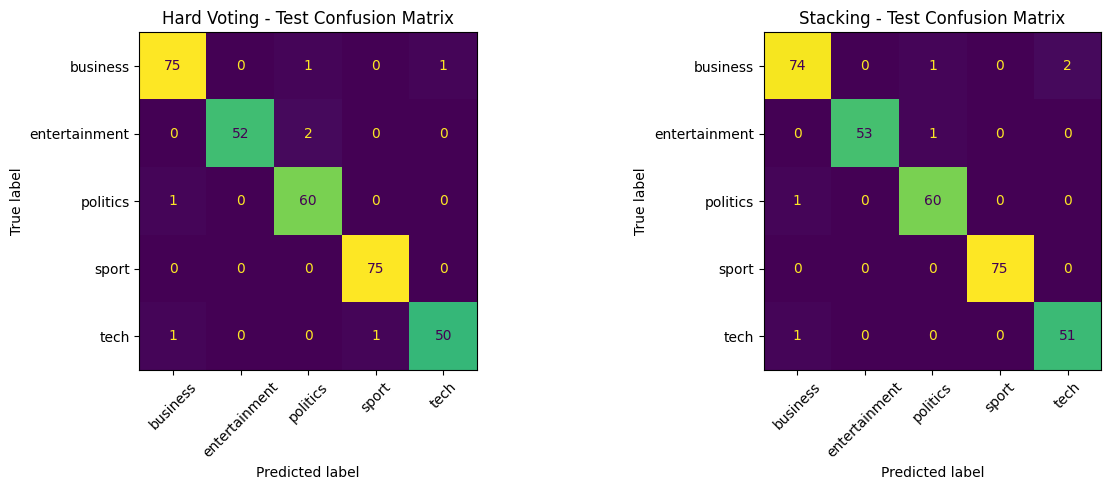

In [ ]:
voting_test_pred = voting_model.predict(X_test_tfidf)
stacking_test_pred = stacking_model.predict(X_test_tfidf)
ensemble_class_order = list(lr_class_order)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, pred) in zip(axes, [("Hard Voting", voting_test_pred),
                                   ("Stacking", stacking_test_pred)]):
    print("=" * 60)
    print(name, "- Test accuracy:", round(accuracy_score(y_test, pred), 4),
          "| Test macro-F1:", round(f1_score(y_test, pred, average="macro"), 4))
    print(classification_report(y_test, pred, labels=ensemble_class_order, digits=4))
    cm = confusion_matrix(y_test, pred, labels=ensemble_class_order)
    ConfusionMatrixDisplay(cm, display_labels=ensemble_class_order).plot(
        ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
    ax.set_title(name + " - Test Confusion Matrix")
plt.tight_layout()
plt.show()

#### Cell 7.6 – Did the Ensembles Help?

Each ensemble is compared with the best base model on the same test set.

In [ ]:
base_test_f1 = {
    "Logistic Regression": f1_score(y_test, lr_y_test_pred, average="macro"),
    "Linear SVM": f1_score(y_test, y_test_pred_svm, average="macro"),
}
best_base_name = max(base_test_f1, key=base_test_f1.get)
best_base_f1 = base_test_f1[best_base_name]
print(f"Best base model on test: {best_base_name} (macro-F1 = {best_base_f1:.4f})\n")

for name, pred in [("Hard Voting", voting_test_pred), ("Stacking", stacking_test_pred)]:
    f1_ens = f1_score(y_test, pred, average="macro")
    diff = f1_ens - best_base_f1
    n_err = int((pred != y_test.values).sum())
    if diff > 1e-9:
        verdict = "improved over"
    elif diff < -1e-9:
        verdict = "was lower than"
    else:
        verdict = "matched"
    print(f"{name}: macro-F1 = {f1_ens:.4f}, {n_err} errors -> {verdict} the best base model "
          f"(difference = {diff:+.4f}).")

Best base model on test: Logistic Regression (macro-F1 = 0.9804)

Hard Voting: macro-F1 = 0.9774, 7 errors -> was lower than the best base model (difference = -0.0029).
Stacking: macro-F1 = 0.9810, 6 errors -> improved over the best base model (difference = +0.0006).


An ensemble helps when its members make different mistakes. Logistic Regression and Linear SVM are both linear models on the same TF-IDF features, so they fail on mostly the same articles (Section 9).

On the 319 test articles, Hard Voting made 7 errors (accuracy 0.9781), one more than Logistic Regression, so it did not improve the result. Stacking made 6 errors (accuracy 0.9812), the same number as Logistic Regression, with a slightly higher macro-F1 (0.9810 against 0.9804). Stacking corrected two of Logistic Regression's errors (`entertainment/257` and `tech/144`) but made two new ones (`politics/017` and `business/211`). A difference this small is not an improvement.

## Section 8: Model Comparison

All four models are compared on the same validation and test sets. The validation columns are used to choose models. The test columns are only reported; they were not used to select any hyperparameter or the model for the GUI.

In [ ]:
import numpy as np
from scipy.stats import binomtest
from sklearn.metrics import precision_recall_fscore_support

class_order = list(lr_class_order)
y_test_arr = np.asarray(y_test)

compare_models = {
    "Logistic Regression": lr_final_model,
    "Linear SVM": svm_final,
    "Hard Voting (LR+SVM+NB)": voting_model,
    "Stacking (LR+SVM+NB)": stacking_model,
}
test_preds = {
    "Logistic Regression": np.asarray(lr_y_test_pred),
    "Linear SVM": np.asarray(y_test_pred_svm),
    "Hard Voting (LR+SVM+NB)": np.asarray(voting_test_pred),
    "Stacking (LR+SVM+NB)": np.asarray(stacking_test_pred),
}

rows = []
for name, model in compare_models.items():
    val_pred = model.predict(X_val_tfidf)
    test_pred = test_preds[name]
    p, r, f, _ = precision_recall_fscore_support(
        y_test_arr, test_pred, average="macro", zero_division=0)
    rows.append({
        "Model": name,
        "Val Accuracy": accuracy_score(y_val, val_pred),
        "Val Macro-F1": f1_score(y_val, val_pred, average="macro"),
        "Test Accuracy": accuracy_score(y_test_arr, test_pred),
        "Test Macro-Precision": p,
        "Test Macro-Recall": r,
        "Test Macro-F1": f,
        "Test Errors (of %d)" % len(y_test_arr): int((test_pred != y_test_arr).sum()),
    })

comparison_df = pd.DataFrame(rows)
display(comparison_df.round(4))

,Model,Val Accuracy,Val Macro-F1,Test Accuracy,Test Macro-Precision,Test Macro-Recall,Test Macro-F1,Test Errors (of 319)
0,Logistic Regression,0.9781,0.9778,0.9812,0.9814,0.9797,0.9804,6
1,Linear SVM,0.9749,0.9741,0.9749,0.9761,0.9726,0.9741,8
2,Hard Voting (LR+SVM+NB),0.9781,0.9778,0.9781,0.9787,0.9764,0.9774,7
3,Stacking (LR+SVM+NB),0.9781,0.9778,0.9812,0.9807,0.9814,0.9810,6


#### Cell 8.2 – Per-Class F1-Score on the Test Set

,Logistic Regression,Linear SVM,Hard Voting (LR+SVM+NB),Stacking (LR+SVM+NB)
business,0.9804,0.9740,0.9740,0.9673
entertainment,0.9811,0.9811,0.9811,0.9907
politics,0.9760,0.9677,0.9677,0.9756
sport,0.9934,0.9868,0.9934,1.0000
tech,0.9709,0.9608,0.9709,0.9714


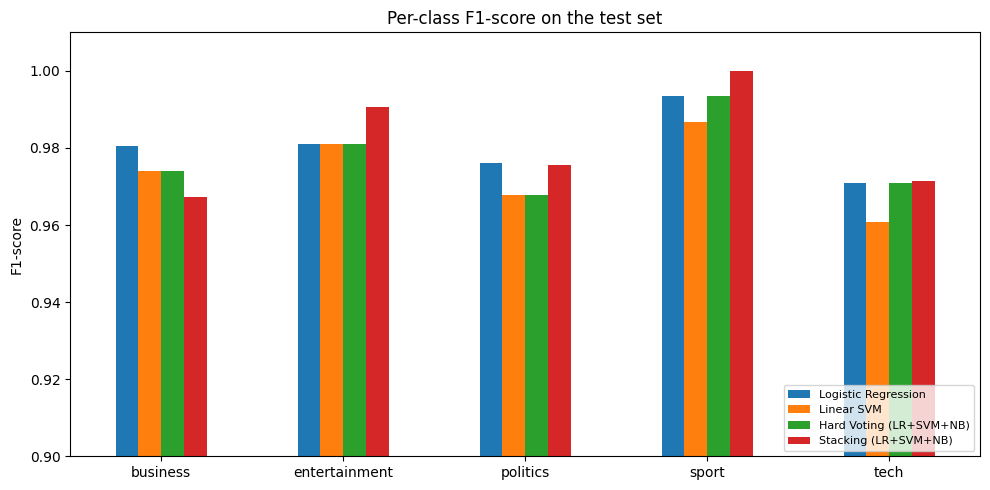

In [ ]:
per_class_f1 = {}
for name, test_pred in test_preds.items():
    _, _, f, _ = precision_recall_fscore_support(
        y_test_arr, test_pred, labels=class_order, zero_division=0)
    per_class_f1[name] = f

per_class_df = pd.DataFrame(per_class_f1, index=class_order)
display(per_class_df.round(4))

ax = per_class_df.plot(kind="bar", figsize=(10, 5))
ax.set_ylim(0.90, 1.01)
ax.set_ylabel("F1-score")
ax.set_title("Per-class F1-score on the test set")
plt.xticks(rotation=0)
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

#### Cell 8.3 – Is the Difference Between Logistic Regression and Linear SVM Significant?

For the test articles where exactly one of the two models is correct, an exact McNemar test checks whether the split differs from 50/50.

In [ ]:
lr_ok = test_preds["Logistic Regression"] == y_test_arr
svm_ok = test_preds["Linear SVM"] == y_test_arr

both_correct = int((lr_ok & svm_ok).sum())
both_wrong = int((~lr_ok & ~svm_ok).sum())
only_lr_correct = int((lr_ok & ~svm_ok).sum())
only_svm_correct = int((~lr_ok & svm_ok).sum())

print("Both correct              :", both_correct)
print("Both wrong                :", both_wrong)
print("Only Logistic Regression correct:", only_lr_correct)
print("Only Linear SVM correct          :", only_svm_correct)

n_disagree = only_lr_correct + only_svm_correct
p_value = binomtest(only_lr_correct, n_disagree, 0.5).pvalue if n_disagree > 0 else 1.0
print(f"\nExact McNemar p-value: {p_value:.3f}")
print("A p-value above 0.05 means the difference is not statistically significant.")

Both correct              : 311
Both wrong                : 6
Only Logistic Regression correct: 2
Only Linear SVM correct          : 0

Exact McNemar p-value: 0.500
A p-value above 0.05 means the difference is not statistically significant.


Logistic Regression is slightly ahead of Linear SVM on validation (macro-F1 0.9778 against 0.9741) and on test (313 against 311 correct articles out of 319). On the articles where the two models disagree, Logistic Regression is right twice and Linear SVM never (exact McNemar p = 0.5), so the difference is not significant.

Both are linear models on the same TF-IDF features. Logistic Regression minimizes the log-loss, Linear SVM maximizes the margin (hinge loss). The Linear SVM reaches a training accuracy of 1.0 for `C ≥ 0.5` (Section 6); the small `C = 0.1` selected on the validation set limits this.

## Section 9: Error Analysis

Which test articles are misclassified, by which models, and why.

In [ ]:
model_cols = {
    "LR": np.asarray(lr_y_test_pred),
    "SVM": np.asarray(y_test_pred_svm),
    "Voting": np.asarray(voting_test_pred),
    "Stacking": np.asarray(stacking_test_pred),
}

pred_df = pd.DataFrame({
    "ID": model_df.loc[y_test.index, "ID"].values,
    "title": df_clean.loc[y_test.index, "title"].values,
    "true": y_test_arr,
}, index=y_test.index)
for col, pred in model_cols.items():
    pred_df[col] = pred

pred_df["n_models_wrong"] = sum((pred_df[col] != pred_df["true"]).astype(int) for col in model_cols)
errors_df = (pred_df[pred_df["n_models_wrong"] > 0]
             .sort_values(["n_models_wrong", "true"], ascending=[False, True]))

print("Test articles misclassified by at least one model:", len(errors_df))
print("Misclassified by ALL four models:", int((pred_df["n_models_wrong"] == len(model_cols)).sum()))
display(errors_df[["ID", "title", "true"] + list(model_cols) + ["n_models_wrong"]])

Test articles misclassified by at least one model: 9
Misclassified by ALL four models: 4


,ID,title,true,LR,SVM,Voting,Stacking,n_models_wrong
241,business/243.txt,Making your office work for you,business,tech,tech,tech,tech,4
252,business/255.txt,Call to overhaul UK state pension,business,politics,politics,politics,politics,4
699,entertainment/202.txt,BBC 'should allow more scrutiny',entertainment,politics,politics,politics,politics,4
1908,tech/133.txt,US blogger fired by her airline,tech,business,business,business,business,4
752,entertainment/257.txt,Row threatens Hendrix museum plan,entertainment,politics,politics,politics,entertainment,3
888,politics/017.txt,Tsunami debt deal to be announced,politics,politics,business,business,business,3
1919,tech/144.txt,Football Manager scores big time,tech,sport,sport,sport,tech,3
210,business/211.txt,Electronics firms eye plasma deal,business,business,business,business,tech,1
1915,tech/140.txt,Players sought for $1m prize,tech,tech,sport,tech,tech,1


#### Cell 9.2 – Confused Categories (true → predicted)

In [ ]:
conf_tables = []
for col, pred in model_cols.items():
    wrong = pred_df[pred != y_test_arr]
    counts = (wrong.assign(predicted=pred[pred != y_test_arr])
                   .groupby(["true", "predicted"]).size().rename(col))
    conf_tables.append(counts)

confusion_pairs = pd.concat(conf_tables, axis=1).fillna(0).astype(int)
confusion_pairs.index.names = ["true category", "predicted as"]
display(confusion_pairs)

LR  SVM  Voting  Stacking
true category predicted as                           
business      politics       1    1       1         1
              tech           1    1       1         2
entertainment politics       2    2       2         1
tech          business       1    1       1         1
              sport          1    2       1         0
politics      business       0    1       1         1

#### Cell 9.3 – Articles Misclassified by at Least Two Models

In [ ]:
hard_cases = errors_df[errors_df["n_models_wrong"] >= 2].head(6)
for idx, row in hard_cases.iterrows():
    print("=" * 80)
    print("ID:", row["ID"], "| True:", row["true"],
          "| LR ->", row["LR"], "| SVM ->", row["SVM"],
          "| Voting ->", row["Voting"], "| Stacking ->", row["Stacking"])
    print("Title:", row["title"])
    print(df_clean.loc[idx, "content_clean"][:450], "...\n")

ID: business/243.txt | True: business | LR -> tech | SVM -> tech | Voting -> tech | Stacking -> tech
Title: Making your office work for you
Our mission to brighten up your working lives continues - and this time, we're taking a long hard look at your offices. Over the next few months, our panel of experts will be listening to your gripes about where you work, and suggesting ways to make your workspace more efficient, more congenial or simply prettier. This week, we're hearing from Marianne Petersen, who is planning to convert a barn in Sweden into a base for her freelance writing wor ...

ID: business/255.txt | True: business | LR -> politics | SVM -> politics | Voting -> politics | Stacking -> politics
Title: Call to overhaul UK state pension
The UK pension system has been branded inadequate and too complex by a leading retirement think-tank. The Pensions Policy Institute (PPI) said replacing the state pension with a "citizen's pension" would help tackle inequality and complexity. The

#### Error Analysis

1. Logistic Regression made 6 errors and Linear SVM made 8 out of 319. All 6 Logistic Regression errors are also Linear SVM errors; the SVM adds `politics/017` and `tech/140`. Four articles are misclassified by all four models, so the models fail on the same hard articles, which is why the ensembles have little room to improve.
2. The most frequent confusion is entertainment → politics (2 articles). `entertainment/202` is about MPs and the National Audit Office scrutinizing the BBC licence fee, and `entertainment/257` is about a dispute between a mayor and local authorities over a house. Both use political and administrative vocabulary.
3. `business/255` (state pension reform proposed by a think-tank) is predicted as politics because it is a policy story. `politics/017` (a G8 debt deal announced by the Chancellor) is predicted as business by the SVM and the ensembles because of the financial vocabulary (debt, interest, billions).
4. `business/243` is about workspaces and working from home, with little financial vocabulary, and is predicted as tech. `tech/133` is about an airline attendant fired over her blog and taking legal action against the airline, and is predicted as business. `tech/144` is about the video game Football Manager and is predicted as sport.
5. Sport is the easiest category (F1 between 0.987 and 1.000 for every model) because its vocabulary is distinctive. Almost all errors are in articles whose topic overlaps with another category, and some of these labels are debatable.
6. TF-IDF ignores word order and context, so it cannot separate football as a sport from football as a video game.

## Section 10: Final Conclusion

In [ ]:
#dataset information
print("DATASET INFORMATION")
print("-" * 60)
print("Name  : BBC News Archive (Kaggle)")
print("Source: https://www.kaggle.com/datasets/hgultekin/bbcnewsarchive")
print("Samples (after removing exact duplicates):", len(model_df))
print("Classes:", sorted(model_df['category'].unique()))
print("Samples per class:")
print(model_df['category'].value_counts().sort_index().to_string())
print()
print("Split  -> Train:", len(X_train), "| Validation:", len(X_val), "| Test:", len(X_test))
print("TF-IDF -> vocabulary size / final feature dimension:", len(tfidf.get_feature_names_out()))

DATASET INFORMATION
------------------------------------------------------------
Name  : BBC News Archive (Kaggle)
Source: https://www.kaggle.com/datasets/hgultekin/bbcnewsarchive
Samples (after removing exact duplicates): 2125
Classes: ['business', 'entertainment', 'politics', 'sport', 'tech']
Samples per class:
category
business         503
entertainment    369
politics         403
sport            503
tech             347

Split  -> Train: 1487 | Validation: 319 | Test: 319
TF-IDF -> vocabulary size / final feature dimension: 10076


In [ ]:
#hyperparameters tried and selected
hyper_df = pd.DataFrame([
    {"Model": "Logistic Regression",
     "Tried": "C in {0.1, 1, 10, 100, 1000} x class_weight in {None, balanced}",
     "Selected (validation macro-F1)": f"C={lr_best_C}, class_weight={lr_best_class_weight}"},
    {"Model": "Linear SVM",
     "Tried": "C in {0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100}",
     "Selected (validation macro-F1)": f"C={best_C}"},
    {"Model": "Complement Naive Bayes (ensemble member)",
     "Tried": "alpha in " + str(nb_alphas),
     "Selected (validation macro-F1)": f"alpha={nb_best_alpha}"},
    {"Model": "Hard Voting / Stacking",
     "Tried": "members use the hyperparameters selected above",
     "Selected (validation macro-F1)": "no extra tuning"},
])
pd.set_option("display.max_colwidth", None)
display(hyper_df)

,Model,Tried,Selected (validation macro-F1)
0,Logistic Regression,"C in {0.1, 1, 10, 100, 1000} x class_weight in {None, balanced}","C=10.0, class_weight=None"
1,Linear SVM,"C in {0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100}",C=0.1
2,Complement Naive Bayes (ensemble member),"alpha in [0.01, 0.05, 0.1, 0.3, 0.5, 1.0]",alpha=0.01
3,Hard Voting / Stacking,members use the hyperparameters selected above,no extra tuning


#### Cell 10.3 – Select the Model for the GUI

The model with the highest validation macro-F1 is selected; a tie goes to the simpler model. The test set plays no part in this choice.

In [ ]:
val_scores = {}
for name, model in compare_models.items():
    val_scores[name] = f1_score(y_val, model.predict(X_val_tfidf), average="macro")

selected_name, best_val = None, -1.0
for name, score in val_scores.items():       # dict order: simple models first
    if score > best_val + 1e-12:
        selected_name, best_val = name, score

print("Validation macro-F1 of every model:")
for name, score in val_scores.items():
    print(f"  {name:28s} {score:.4f}")
print(f"\nSelected for the GUI: {selected_name} (validation macro-F1 = {best_val:.4f})")

sel_pred = test_preds[selected_name]
print(f"Its test results (reported, not used for selection): "
      f"accuracy = {accuracy_score(y_test_arr, sel_pred):.4f}, "
      f"macro-F1 = {f1_score(y_test_arr, sel_pred, average='macro'):.4f}")

Validation macro-F1 of every model:
  Logistic Regression          0.9778
  Linear SVM                   0.9741
  Hard Voting (LR+SVM+NB)      0.9778
  Stacking (LR+SVM+NB)         0.9778

Selected for the GUI: Logistic Regression (validation macro-F1 = 0.9778)
Its test results (reported, not used for selection): accuracy = 0.9812, macro-F1 = 0.9804


#### Final Conclusion

We classified 2,125 BBC news articles into 5 categories. After cleaning and removing exact duplicates, the data was split into 1,487 training, 319 validation and 319 test articles (70/15/15, stratified, identical articles kept in the same split) and converted into 10,076 TF-IDF features. Hyperparameters were selected on the validation set and each model was evaluated once on the test set.

| Model | Test accuracy | Test macro-F1 | Test errors |
|---|---|---|---|
| Logistic Regression (C = 10) | 0.9812 | 0.9804 | 6 |
| Linear SVM (C = 0.1) | 0.9749 | 0.9741 | 8 |
| Hard Voting | 0.9781 | 0.9774 | 7 |
| Stacking | 0.9812 | 0.9810 | 6 |

- Both required models perform very well because the five categories use clearly different vocabulary. Logistic Regression is ahead by two articles, which is not statistically significant (McNemar p = 0.5), so the two models are practically equivalent.
- The ensembles did not give a real improvement. Hard Voting made one more error than Logistic Regression, and Stacking made the same number (it fixed two articles and broke two others). The base models already make very few errors, and mostly on the same articles.
- The models fail on articles whose topic overlaps with another category: entertainment articles about institutions predicted as politics, a pension story predicted as politics, a football video game predicted as sport.
- Logistic Regression was selected for the GUI by validation macro-F1 (0.9778, tied with the two ensembles; the simplest model is kept).

**Limitations:** TF-IDF ignores word order and meaning, and the dataset is small and comes from one source. On 319 test articles the accuracy has a margin of about ±1.5 points.